In [1]:
import os

import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from skimage import filters
from scipy import stats

In [2]:
mesh_database_path = r"../99_broccoli_models"

mesh_db = []
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db.append(os.path.join(mesh_database_path, file))

In [3]:
def mesh2pcd(mesh):
    mesh_pcd = o3d.geometry.PointCloud()
    mesh_pcd.points = mesh.vertices
    mesh_pcd.colors = mesh.vertex_colors
    mesh_pcd.normals = mesh.vertex_normals
    
    return mesh_pcd

def project_points_on_vector(points, vector):
    """
    把点投影到给定向量上
    输入：points: nx3的三维点
         vector: 1x3的向量
    输出：投影后的点(在空间中的位置)
    """
    v_norm = np.sqrt(sum(vector**2))
    
    return (np.dot(points, vector.reshape(3,1))/v_norm**2)*vector

In [68]:
# test mesh
# mesh = o3d.io.read_triangle_mesh(mesh_db[10])
mesh = o3d.io.read_triangle_mesh(mesh_db[190])

In [69]:
pcd = mesh2pcd(mesh)

In [70]:
# 坐标轴 RGB -> XYZ
line_set = o3d.geometry.LineSet()

line_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0],[0.1,0,0],[0,0.1,0], [0,0,0.1]]))
line_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
line_set.colors = o3d.utility.Vector3dVector(np.array([[1,0,0],[0,1,0],[0,0,1]]))

In [71]:
# 计算定向边界框
obb = pcd.get_oriented_bounding_box()
obb.color = (0, 0, 0)

In [72]:
# 矩阵的正交方向
ur_set = o3d.geometry.LineSet()

ur_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0], obb.R[:,0]/10, obb.R[:,1]/10, obb.R[:,2]/10]))
ur_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
ur_set.colors = o3d.utility.Vector3dVector(np.array([[1,1,0],[0,1,1],[1,0,1]]))

In [73]:
# 可视化
o3d.visualization.draw_geometries([pcd, line_set, obb, ur_set])

RGB是坐标轴，其他颜色的是orient

![](images/03_obb_orient.png)

In [9]:
# find the maximum edge and its vector:
main_idx = np.argmax(obb.extent)

In [10]:
pcd_on_z = project_points_on_vector(np.asarray(pcd.points), obb.R[:,main_idx])

In [11]:
temp_pcd = o3d.geometry.PointCloud()
temp_pcd.points = o3d.utility.Vector3dVector(pcd_on_z)
temp_pcd.colors = mesh.vertex_colors

In [13]:
o3d.visualization.draw_geometries([temp_pcd, line_set, obb])

![](images/03_longest_project.png)

In [12]:
# project on 
pcd_on_z_unit = (pcd_on_z / obb.R[:,main_idx])[:,0]

In [13]:
# calculate the direction

## calculate the middle point
pmax = pcd_on_z_unit.max()
pmin = pcd_on_z_unit.min()
pmid = (pmax + pmin) / 2
pmean = pcd_on_z_unit.mean()
pmedian = np.median(pcd_on_z_unit)

## calculate the kde peak
kde = stats.gaussian_kde(pcd_on_z_unit)
xx = np.linspace(pmin, pmax, 1000)
yy = kde(xx)

## calculate the otsu thresh
otsu = filters.threshold_otsu(pcd_on_z_unit)

max_peak = xx[np.argmax(yy)]

## calculate the local valley
peak = (np.diff(np.sign(np.diff(yy))) < 0).nonzero()[0] + 1 
valley = (np.diff(np.sign(np.diff(yy))) > 0).nonzero()[0] + 1 

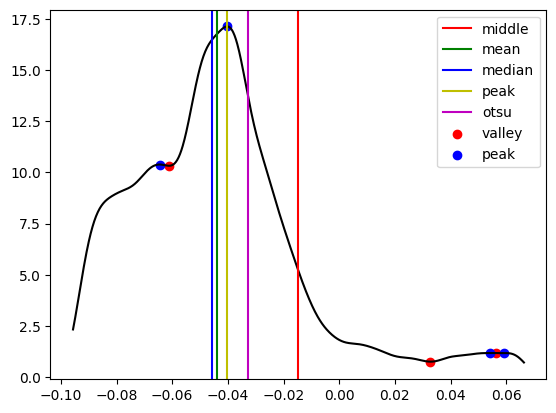

In [14]:
fig, ax = plt.subplots(1,1)
ax.plot(xx, yy, color='k')
ax.axvline(x=pmid, color='r', label="middle")
ax.axvline(x=pmean, color='g', label="mean")
ax.axvline(x=pmedian, color='b', label="median")
ax.axvline(x=max_peak, color='y', label="peak")
ax.axvline(x=otsu, color='m', label="otsu")
ax.scatter(xx[valley], yy[valley], color='r', label="valley")
ax.scatter(xx[peak], yy[peak], color='b', label="peak")

plt.legend()
plt.show()

In [15]:
if pmean < pmid:
    vz = obb.R[:,main_idx] * -1
else:
    vz = obb.R[:,main_idx]

In [27]:
vz

array([-0.04367782,  0.92197856,  0.38476978])

使用Keans聚类呢？

In [16]:
from sklearn.cluster import KMeans

In [17]:
pcd_on_z_unit

array([-0.03046579, -0.03147176, -0.03198903, ..., -0.02123335,
       -0.02334574, -0.02334574])

In [18]:
rgb = np.array(pcd.colors)
rgb

array([[0.239216  , 0.29803899, 0.133333  ],
       [0.44705901, 0.52156901, 0.372549  ],
       [0.388235  , 0.46274501, 0.26274499],
       ...,
       [0.32941201, 0.388235  , 0.25490201],
       [0.40392199, 0.50196099, 0.27058801],
       [0.40392199, 0.50196099, 0.27058801]])

In [19]:
X = np.concatenate([pcd_on_z_unit[:,None], rgb], axis=1)
X

array([[-0.03046579,  0.239216  ,  0.29803899,  0.133333  ],
       [-0.03147176,  0.44705901,  0.52156901,  0.372549  ],
       [-0.03198903,  0.388235  ,  0.46274501,  0.26274499],
       ...,
       [-0.02123335,  0.32941201,  0.388235  ,  0.25490201],
       [-0.02334574,  0.40392199,  0.50196099,  0.27058801],
       [-0.02334574,  0.40392199,  0.50196099,  0.27058801]])

In [20]:
kmeans = KMeans(n_clusters=2, random_state=0, n_init="auto")

In [28]:
kmeans.fit(rgb)

KMeans(n_clusters=2, n_init='auto', random_state=0)

In [29]:
kmeans.labels_

array([0, 1, 1, ..., 0, 1, 1], dtype=int32)

visualize the results

In [30]:
label_rgb = np.zeros((X.shape[0], 3))

label_rgb[kmeans.labels_ == 0,:] = np.array([1,0,0])

In [31]:
labeled_pcd = o3d.geometry.PointCloud()

labeled_pcd.points = o3d.utility.Vector3dVector(pcd.points)
labeled_pcd.colors = o3d.utility.Vector3dVector(label_rgb)

In [32]:
o3d.visualization.draw_geometries([labeled_pcd])

judge which class is crown class

In [33]:
c0 = np.where(kmeans.labels_ == 0)[0]
c1 = np.where(kmeans.labels_ == 1)[0]

In [34]:
pcd_c0 = pcd.select_by_index(c0)
pcd_c1 = pcd.select_by_index(c1)

In [44]:
z0 = pcd_on_z_unit[kmeans.labels_ == 0]
z1 = pcd_on_z_unit[kmeans.labels_ == 1]
z0_mean = z0.mean()
z1_mean = z1.mean()

if pmean < pmid:
    # vz = obb.R[:,main_idx] * -1
    if z0_mean < z1_mean:
        print('z0 is crown')
    else:
        print('z1 is crown')
else:
    # vz = obb.R[:,main_idx]
    if z0_mean < z1_mean:
        # return z1
        print('z1 is crown')
    else:
        print('z0 is crown')


z0 is crown


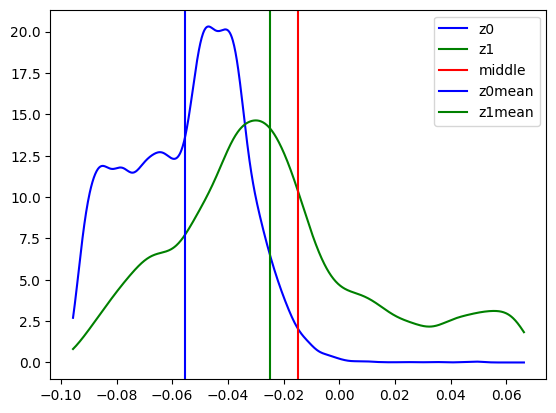

In [45]:
kde0 = stats.gaussian_kde(z0)
xx0 = np.linspace(pmin, pmax, 1000)
yy0 = kde0(xx0)

kde1 = stats.gaussian_kde(z1)
xx1 = np.linspace(pmin, pmax, 1000)
yy1 = kde1(xx1)

fig, ax = plt.subplots(1,1)
ax.plot(xx0, yy0,color='b', label='z0')
ax.plot(xx1, yy1,color='g', label='z1')

ax.axvline(x=pmid, color='r', label="middle")

ax.axvline(x=z0_mean, color='b', label="z0mean")
ax.axvline(x=z1_mean, color='g',label="z1mean")

plt.legend()
plt.show()

In [46]:
o3d.visualization.draw_geometries([pcd_c0]) 

In [62]:
pcd_c0_denoised, selected_idx = pcd_c0.remove_radius_outlier(20, 0.01)

In [56]:
o3d.visualization.draw_geometries([pcd_c0_denoised]) 

noises return back to index from original masks

In [59]:
label_rgb[c0[selected_idx],:] = np.array([0,1,0])

In [60]:
labeled_pcd = o3d.geometry.PointCloud()

labeled_pcd.points = o3d.utility.Vector3dVector(pcd.points)
labeled_pcd.colors = o3d.utility.Vector3dVector(label_rgb)

In [61]:
o3d.visualization.draw_geometries([labeled_pcd])

# organize to a function, output the colored point cloud

The green as crown, red as removed noise, and black as stem

In [90]:
def segment_crown(head_pcd, denoise_count=20, denoise_radius=0.01):
    # 计算定向边界框
    obb = head_pcd.get_oriented_bounding_box()
    # find the maximum edge and its vector:
    main_idx = np.argmax(obb.extent)

    # 把点云投影到最长轴上
    # pcd_on_z -> (x, y, z) 3D
    pcd_on_z = project_points_on_vector(np.asarray(head_pcd.points), obb.R[:,main_idx])
    # project 3D line to 1D
    pcd_on_z_unit = (pcd_on_z / obb.R[:,main_idx])[:,0]

    # use Kmeans to classify points to 2 class by color
    rgb = np.asarray(head_pcd.colors)
    kmeans = KMeans(n_clusters=2, random_state=0, n_init="auto")
    kmeans.fit(rgb)

    ## the z axis points of each class
    z0 = pcd_on_z_unit[kmeans.labels_ == 0]
    z1 = pcd_on_z_unit[kmeans.labels_ == 1]
    z0_mean = z0.mean()
    z1_mean = z1.mean()

    # find out which is the crown class
    ## calculate the direction
    pmax = pcd_on_z_unit.max()
    pmin = pcd_on_z_unit.min()
    pmid = (pmax + pmin) / 2
    pmean = pcd_on_z_unit.mean()

    if pmean < pmid:
        # The crown is in the -z direction (points KDE line)
        #
        # |        pmean
        # |       . |    pmid
        # |     .   |  . ||
        # |   .     |    ||  .  
        # | .       |    ||       ^   .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx] * -1
        if z0_mean < z1_mean:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0
        else:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
    else:
        # The crown is in the +z direction (points KDE line)
        #
        # |                 pmean
        # |            pmid   |  .
        # |             ||  . |    .
        # |           . ||    |      .
        # | .     ^     ||    |        .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx]
        if z0_mean < z1_mean:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
        else:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0

    crown_int_idx = np.where(crown_bool_idx)[0]

    crown_pcd = pcd.select_by_index(crown_int_idx)
    crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_radius_outlier(denoise_count, denoise_radius)
    crown_denoised_int_idx = crown_int_idx[keeped_int_idx]

    ## create a results pcd, 
    labeled_pcd = o3d.geometry.PointCloud()

    ### black for stem
    label_rgb = np.zeros((len(head_pcd.points), 3))
    ### red for denoised
    label_rgb[crown_bool_idx, :] = np.array([1,0,0])
    ### green for crown
    label_rgb[crown_denoised_int_idx,:] = np.array([0,1,0])

    labeled_pcd.points = o3d.utility.Vector3dVector(head_pcd.points)
    labeled_pcd.colors = o3d.utility.Vector3dVector(label_rgb)

    #################
    ## draw figures
    #################
    kde0 = stats.gaussian_kde(z0)
    xx0 = np.linspace(pmin, pmax, 1000)
    yy0 = kde0(xx0)

    kde1 = stats.gaussian_kde(z1)
    xx1 = np.linspace(pmin, pmax, 1000)
    yy1 = kde1(xx1)

    fig, ax = plt.subplots(1,1)
    ax.plot(xx0, yy0,color='b', label='z0')
    ax.plot(xx1, yy1,color='g', label='z1')

    ax.axvline(x=pmid, color='r', label="middle")

    ax.axvline(x=z0_mean, color='b', label="z0mean")
    ax.axvline(x=z1_mean, color='g',label="z1mean")

    plt.legend()
    plt.show()

    return crown_pcd_denoised, labeled_pcd, crown_denoised_int_idx

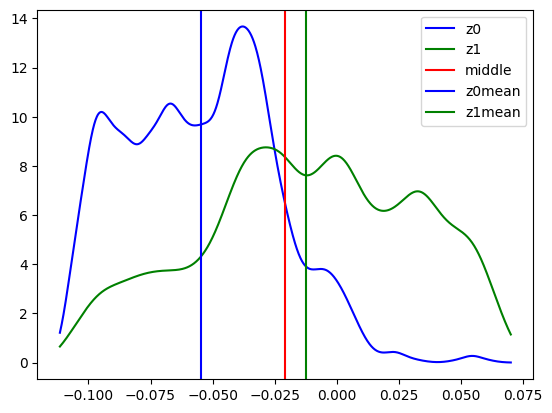

In [95]:
def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(mesh_db[190]))

_, lb_pcd, _ = segment_crown(def_test_pcd, 100, 0.01)

o3d.visualization.draw_geometries([lb_pcd])